In [2]:
gold_data = pd.read_csv("../data/gld_price_data.csv")

gold_data.head()


,Date,SPX,GLD,USO,SLV,EUR/USD
0,1/2/2008,1447.160034,84.860001,78.470001,15.180,1.471692
1,1/3/2008,1447.160034,85.570000,78.370003,15.285,1.474491
2,1/4/2008,1411.630005,85.129997,77.309998,15.167,1.475492
3,1/7/2008,1416.180054,84.769997,75.500000,15.053,1.468299
4,1/8/2008,1390.189941,86.779999,76.059998,15.590,1.557099


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Gold Price Prediction Project Started!")

Gold Price Prediction Project Started!


In [3]:
gold_data.shape


(2290, 6)

In [4]:
gold_data.info()


<class 'pandas.DataFrame'>
RangeIndex: 2290 entries, 0 to 2289
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Date     2290 non-null   str    
 1   SPX      2290 non-null   float64
 2   GLD      2290 non-null   float64
 3   USO      2290 non-null   float64
 4   SLV      2290 non-null   float64
 5   EUR/USD  2290 non-null   float64
dtypes: float64(5), str(1)
memory usage: 127.5 KB


In [5]:
gold_data.describe()


,SPX,GLD,USO,SLV,EUR/USD
count,2290.000000,2290.000000,2290.000000,2290.000000,2290.000000
mean,1654.315776,122.732875,31.842221,20.084997,1.283653
std,519.111540,23.283346,19.523517,7.092566,0.131547
min,676.530029,70.000000,7.960000,8.850000,1.039047
25%,1239.874969,109.725000,14.380000,15.570000,1.171313
50%,1551.434998,120.580002,33.869999,17.268500,1.303297
75%,2073.010070,132.840004,37.827501,22.882500,1.369971
max,2872.870117,184.589996,117.480003,47.259998,1.598798


In [6]:
gold_data.isnull().sum()

Date       0
SPX        0
GLD        0
USO        0
SLV        0
EUR/USD    0
dtype: int64

In [7]:
gold_data['Date'] = pd.to_datetime(gold_data['Date'])

gold_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2290 entries, 0 to 2289
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Date     2290 non-null   datetime64[us]
 1   SPX      2290 non-null   float64       
 2   GLD      2290 non-null   float64       
 3   USO      2290 non-null   float64       
 4   SLV      2290 non-null   float64       
 5   EUR/USD  2290 non-null   float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 107.5 KB


In [8]:
gold_data.duplicated().sum()


np.int64(0)

In [9]:
correlation = gold_data.drop(columns=['Date']).corr()

print(correlation['GLD'].sort_values(ascending=False))

GLD        1.000000
SLV        0.866632
SPX        0.049345
EUR/USD   -0.024375
USO       -0.186360
Name: GLD, dtype: float64


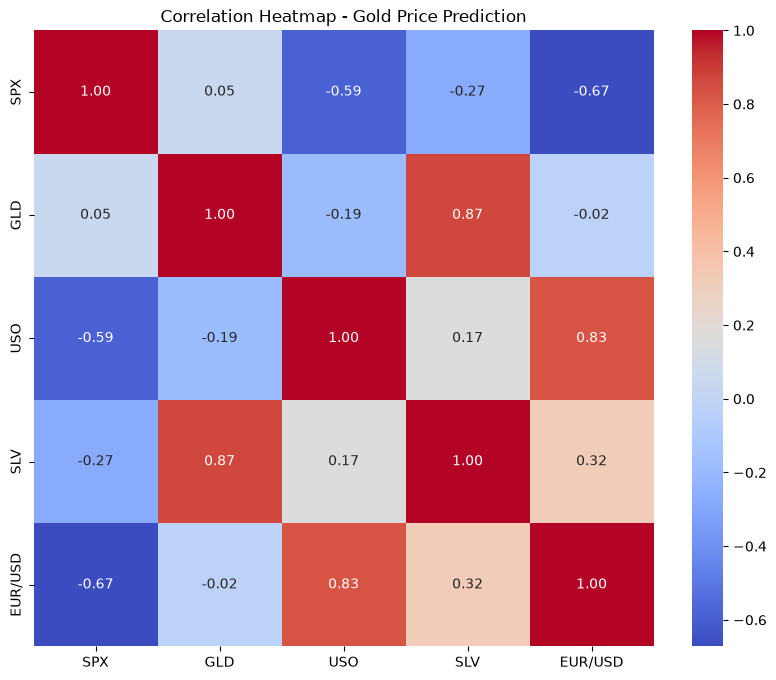

In [10]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap - Gold Price Prediction')
plt.show()

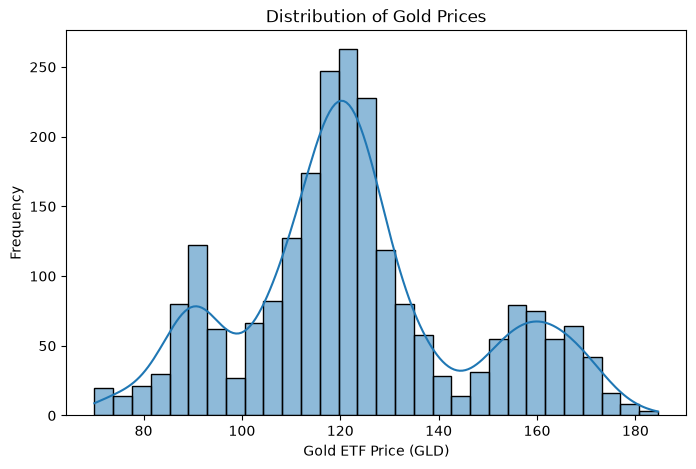

In [11]:
plt.figure(figsize=(8, 5))

sns.histplot(gold_data['GLD'], bins=30, kde=True)

plt.title('Distribution of Gold Prices')
plt.xlabel('Gold ETF Price (GLD)')
plt.ylabel('Frequency')

plt.show()

In [12]:
X = gold_data.drop(['Date', 'GLD'], axis=1)

y = gold_data['GLD']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2290, 4)
Target shape: (2290,)


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1832, 4)
Testing features: (458, 4)
Training target: (1832,)
Testing target: (458,)


In [14]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

In [15]:
lr_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 0.01, -0.25, 3.13,-10.88]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['SPX','USO','SLV','EUR/USD']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,70.84
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,4


In [16]:
lr_predictions = lr_model.predict(X_test)

print(lr_predictions[:10])

[122.51325689 127.0907545  125.50313349 104.54764991 124.90068634
 116.586858   123.04583828 125.14446632 112.05259024 104.88193814]


In [17]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values[:10],
    'Predicted Price': lr_predictions[:10]
})

print(comparison)

   Actual Price  Predicted Price
0    122.320000       122.513257
1    129.899994       127.090754
2    126.980003       125.503133
3     96.500000       104.547650
4    117.580002       124.900686
5    115.000000       116.586858
6    125.440002       123.045838
7    116.930000       125.144466
8    108.220001       112.052590
9     98.830002       104.881938


In [18]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

In [19]:
lr_r2 = r2_score(y_test, lr_predictions)

lr_mae = mean_absolute_error(y_test, lr_predictions)

lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))

print("Linear Regression Results")
print("R2 Score:", lr_r2)
print("MAE:", lr_mae)
print("RMSE:", lr_rmse)

Linear Regression Results
R2 Score: 0.8975640982991402
MAE: 5.69590064426929
RMSE: 7.494370835167288


In [20]:
lr_results = {
    'Model': 'Linear Regression',
    'R2 Score': lr_r2,
    'MAE': lr_mae,
    'RMSE': lr_rmse
}

print(lr_results)

{'Model': 'Linear Regression', 'R2 Score': 0.8975640982991402, 'MAE': 5.69590064426929, 'RMSE': np.float64(7.494370835167288)}


In [21]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [22]:
rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [23]:
rf_predictions = rf_model.predict(X_test)

print(rf_predictions[:10])

[122.46679941 130.28880316 127.70369937  96.69889736 118.97240056
 114.50079901 124.67450149 117.84549963 108.10790103  98.21069968]


In [24]:
rf_r2 = r2_score(y_test, rf_predictions)

rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

print("Random Forest Results")
print("R2 Score:", rf_r2)
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)

Random Forest Results
R2 Score: 0.9900139197031975
MAE: 1.2365668079257677
RMSE: 2.339950167171593


In [25]:
model_comparison = pd.DataFrame([
    lr_results,
    {
        'Model': 'Random Forest',
        'R2 Score': rf_r2,
        'MAE': rf_mae,
        'RMSE': rf_rmse
    }
])

print(model_comparison)

               Model  R2 Score       MAE      RMSE
0  Linear Regression  0.897564  5.695901  7.494371
1      Random Forest  0.990014  1.236567  2.339950


In [26]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

   Feature  Importance
2      SLV    0.763365
0      SPX    0.174118
1      USO    0.035691
3  EUR/USD    0.026826


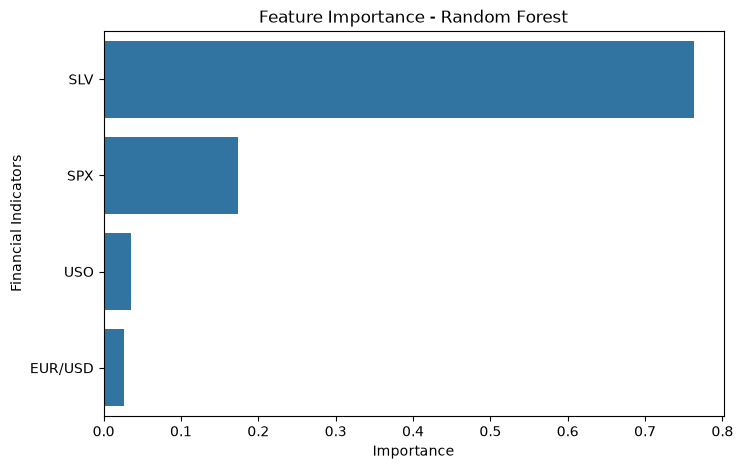

In [27]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Financial Indicators')

plt.show()

In [28]:
gold_data = gold_data.sort_values(
    by='Date'
).reset_index(drop=True)

In [29]:
X_time = gold_data.drop(
    ['Date', 'GLD'], axis=1
)

y_time = gold_data['GLD']

In [30]:
split_index = int(len(gold_data) * 0.8)

X_train_time = X_time.iloc[:split_index]
X_test_time = X_time.iloc[split_index:]

y_train_time = y_time.iloc[:split_index]
y_test_time = y_time.iloc[split_index:]

In [31]:
print("Training:", X_train_time.shape)
print("Testing:", X_test_time.shape)

print("\nTraining date range:")
print(gold_data['Date'].iloc[0])
print(gold_data['Date'].iloc[split_index - 1])

print("\nTesting date range:")
print(gold_data['Date'].iloc[split_index])
print(gold_data['Date'].iloc[-1])

Training: (1832, 4)
Testing: (458, 4)

Training date range:
2008-01-02 00:00:00
2016-04-13 00:00:00

Testing date range:
2016-04-14 00:00:00
2018-05-16 00:00:00


In [32]:
rf_time_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_time_model.fit(X_train_time, y_train_time)

rf_time_predictions = rf_time_model.predict(X_test_time)

In [33]:
rf_time_r2 = r2_score(
    y_test_time, rf_time_predictions
)

rf_time_mae = mean_absolute_error(
    y_test_time, rf_time_predictions
)

rf_time_rmse = np.sqrt(
    mean_squared_error(y_test_time, rf_time_predictions)
)

print("Chronological Random Forest Results")
print("R2:", rf_time_r2)
print("MAE:", rf_time_mae)
print("RMSE:", rf_time_rmse)

Chronological Random Forest Results
R2: -0.4555616327825618
MAE: 4.494724715764186
RMSE: 5.840255633668764


In [34]:
lr_time_model = LinearRegression()

lr_time_model.fit(X_train_time, y_train_time)

lr_time_predictions = lr_time_model.predict(X_test_time)

In [35]:
lr_time_r2 = r2_score(
    y_test_time, lr_time_predictions
)

lr_time_mae = mean_absolute_error(
    y_test_time, lr_time_predictions
)

lr_time_rmse = np.sqrt(
    mean_squared_error(y_test_time, lr_time_predictions)
)

print("Chronological Linear Regression Results")
print("R2:", lr_time_r2)
print("MAE:", lr_time_mae)
print("RMSE:", lr_time_rmse)

Chronological Linear Regression Results
R2: -0.44403801917106467
MAE: 4.641271350181605
RMSE: 5.8170911787504425


In [36]:
time_comparison = pd.DataFrame([
    {
        'Model': 'Linear Regression',
        'R2': lr_time_r2,
        'MAE': lr_time_mae,
        'RMSE': lr_time_rmse
    },
    {
        'Model': 'Random Forest',
        'R2': rf_time_r2,
        'MAE': rf_time_mae,
        'RMSE': rf_time_rmse
    }
])

print(time_comparison)

               Model        R2       MAE      RMSE
0  Linear Regression -0.444038  4.641271  5.817091
1      Random Forest -0.455562  4.494725  5.840256


In [37]:
lr_time_model = LinearRegression()

lr_time_model.fit(X_train_time, y_train_time)

lr_time_predictions = lr_time_model.predict(X_test_time)

In [38]:
lr_time_r2 = r2_score(
    y_test_time, lr_time_predictions
)

lr_time_mae = mean_absolute_error(
    y_test_time, lr_time_predictions
)

lr_time_rmse = np.sqrt(
    mean_squared_error(y_test_time, lr_time_predictions)
)

print("Chronological Linear Regression Results")
print("R2:", lr_time_r2)
print("MAE:", lr_time_mae)
print("RMSE:", lr_time_rmse)

Chronological Linear Regression Results
R2: -0.44403801917106467
MAE: 4.641271350181605
RMSE: 5.8170911787504425


In [39]:
time_comparison = pd.DataFrame([
    {
        'Model': 'Linear Regression',
        'R2': lr_time_r2,
        'MAE': lr_time_mae,
        'RMSE': lr_time_rmse
    },
    {
        'Model': 'Random Forest',
        'R2': rf_time_r2,
        'MAE': rf_time_mae,
        'RMSE': rf_time_rmse
    }
])

print(time_comparison)

               Model        R2       MAE      RMSE
0  Linear Regression -0.444038  4.641271  5.817091
1      Random Forest -0.455562  4.494725  5.840256


In [40]:
forecast_data = gold_data.copy()

forecast_data = forecast_data.sort_values(
    by='Date'
).reset_index(drop=True)

In [41]:
forecast_data['Target'] = forecast_data['GLD'].shift(-1)

In [42]:
forecast_data = forecast_data.dropna()

forecast_data = forecast_data.reset_index(drop=True)

In [43]:
forecast_data.head()

,Date,SPX,GLD,USO,SLV,EUR/USD,Target
0,2008-01-02,1447.160034,84.860001,78.470001,15.180,1.471692,85.570000
1,2008-01-03,1447.160034,85.570000,78.370003,15.285,1.474491,85.129997
2,2008-01-04,1411.630005,85.129997,77.309998,15.167,1.475492,84.769997
3,2008-01-07,1416.180054,84.769997,75.500000,15.053,1.468299,86.779999
4,2008-01-08,1390.189941,86.779999,76.059998,15.590,1.557099,86.550003


In [44]:
forecast_data.shape

(2289, 7)

In [45]:
# Separate features and target
X_forecast = forecast_data.drop(['Date', 'Target'], axis=1)
y_forecast = forecast_data['Target']

# Split chronologically: first 80% for training, last 20% for testing
split_index = int(len(forecast_data) * 0.8)

X_train_forecast = X_forecast.iloc[:split_index]
X_test_forecast = X_forecast.iloc[split_index:]

y_train_forecast = y_forecast.iloc[:split_index]
y_test_forecast = y_forecast.iloc[split_index:]

print("Training data:", X_train_forecast.shape)
print("Testing data:", X_test_forecast.shape)

print("Training period:",
      forecast_data['Date'].iloc[0],
      "to",
      forecast_data['Date'].iloc[split_index - 1])

print("Testing period:",
      forecast_data['Date'].iloc[split_index],
      "to",
      forecast_data['Date'].iloc[-1])

Training data: (1831, 5)
Testing data: (458, 5)
Training period: 2008-01-02 00:00:00 to 2016-04-12 00:00:00
Testing period: 2016-04-13 00:00:00 to 2018-05-14 00:00:00


In [46]:
# Baseline: predict the next GLD price using the current GLD price
baseline_predictions = X_test_forecast['GLD']

# Evaluate baseline performance
baseline_r2 = r2_score(y_test_forecast, baseline_predictions)
baseline_mae = mean_absolute_error(y_test_forecast, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test_forecast, baseline_predictions))

print("Baseline Model Performance")
print("---------------------------")
print("R2 Score:", round(baseline_r2, 4))
print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))

Baseline Model Performance
---------------------------
R2 Score: 0.9583
MAE: 0.7309
RMSE: 0.9888


In [47]:
# Train the Random Forest model
rf_forecast_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_forecast_model.fit(X_train_forecast, y_train_forecast)

# Make predictions
rf_forecast_predictions = rf_forecast_model.predict(X_test_forecast)

# Evaluate performance
rf_forecast_r2 = r2_score(y_test_forecast, rf_forecast_predictions)
rf_forecast_mae = mean_absolute_error(y_test_forecast, rf_forecast_predictions)
rf_forecast_rmse = np.sqrt(
    mean_squared_error(y_test_forecast, rf_forecast_predictions)
)

print("Random Forest Forecast Performance")
print("----------------------------------")
print("R2 Score:", round(rf_forecast_r2, 4))
print("MAE:", round(rf_forecast_mae, 4))
print("RMSE:", round(rf_forecast_rmse, 4))

Random Forest Forecast Performance
----------------------------------
R2 Score: 0.9217
MAE: 1.0647
RMSE: 1.3548


In [48]:
forecast_comparison = pd.DataFrame({
    'Model': ['Persistence Baseline', 'Random Forest'],
    'R2 Score': [baseline_r2, rf_forecast_r2],
    'MAE': [baseline_mae, rf_forecast_mae],
    'RMSE': [baseline_rmse, rf_forecast_rmse]
})

forecast_comparison


,Model,R2 Score,MAE,RMSE
0,Persistence Baseline,0.958276,0.730930,0.988805
1,Random Forest,0.921667,1.064749,1.354846


### Forecasting Model Comparison

The Persistence Baseline outperformed the Random Forest model across all three evaluation metrics.

- Persistence Baseline achieved an R² score of 0.9583, MAE of 0.7309 and RMSE of 0.9888.
- Random Forest achieved an R² score of 0.9217, MAE of 1.0647 and RMSE of 1.3548.

This indicates that using the current GLD price as the next-observation prediction was more effective than the Random Forest model on this test period.

The results highlight the importance of chronological validation and comparing machine-learning models against simple baseline approaches.

In [49]:
# Create a copy of the original dataset
feature_data = gold_data.copy()

# Sort data by date
feature_data = feature_data.sort_values(by='Date').reset_index(drop=True)

# Create previous observation price features
feature_data['GLD_Lag1'] = feature_data['GLD'].shift(1)
feature_data['GLD_Lag5'] = feature_data['GLD'].shift(5)

# Calculate change in GLD price
feature_data['GLD_Change1'] = feature_data['GLD'].diff(1)

# Create next-observation target
feature_data['Target'] = feature_data['GLD'].shift(-1)

# Remove rows with missing values
feature_data = feature_data.dropna().reset_index(drop=True)

print("Dataset shape:", feature_data.shape)
feature_data.head()

Dataset shape: (2284, 10)


,Date,SPX,GLD,USO,SLV,EUR/USD,GLD_Lag1,GLD_Lag5,GLD_Change1,Target
0,2008-01-09,1409.130005,86.550003,75.250000,15.520000,1.466405,86.779999,84.860001,-0.229996,88.250000
1,2008-01-10,1420.329956,88.250000,74.019997,16.061001,1.480100,86.550003,85.570000,1.699997,88.580002
2,2008-01-11,1401.020020,88.580002,73.089996,16.077000,1.479006,88.250000,85.129997,0.330002,89.540001
3,2008-01-14,1416.250000,89.540001,74.250000,16.280001,1.486900,88.580002,84.769997,0.959999,87.989998
4,2008-01-15,1380.949951,87.989998,72.779999,15.834000,1.480210,89.540001,86.779999,-1.550003,86.699997


In [50]:
# Select features and target
X_features = feature_data.drop(['Date', 'Target'], axis=1)
y_features = feature_data['Target']

# Chronological 80-20 split
split_index = int(len(feature_data) * 0.8)

X_train_features = X_features.iloc[:split_index]
X_test_features = X_features.iloc[split_index:]

y_train_features = y_features.iloc[:split_index]
y_test_features = y_features.iloc[split_index:]

print("Training data:", X_train_features.shape)
print("Testing data:", X_test_features.shape)

Training data: (1827, 8)
Testing data: (457, 8)


In [51]:
# Create and train the Random Forest model
rf_feature_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_feature_model.fit(X_train_features, y_train_features)

# Make predictions
rf_feature_predictions = rf_feature_model.predict(X_test_features)

# Calculate evaluation metrics
rf_feature_r2 = r2_score(y_test_features, rf_feature_predictions)
rf_feature_mae = mean_absolute_error(y_test_features, rf_feature_predictions)
rf_feature_rmse = np.sqrt(
    mean_squared_error(y_test_features, rf_feature_predictions)
)

print("Random Forest with Engineered Features")
print("---------------------------------------")
print("R2 Score:", round(rf_feature_r2, 4))
print("MAE:", round(rf_feature_mae, 4))
print("RMSE:", round(rf_feature_rmse, 4))

Random Forest with Engineered Features
---------------------------------------
R2 Score: 0.9206
MAE: 1.0738
RMSE: 1.3648


In [52]:
final_comparison = pd.DataFrame({
    'Model': [
        'Persistence Baseline',
        'Random Forest',
        'Random Forest with Engineered Features'
    ],
    'R2 Score': [
        baseline_r2,
        rf_forecast_r2,
        rf_feature_r2
    ],
    'MAE': [
        baseline_mae,
        rf_forecast_mae,
        rf_feature_mae
    ],
    'RMSE': [
        baseline_rmse,
        rf_forecast_rmse,
        rf_feature_rmse
    ]
})

final_comparison

,Model,R2 Score,MAE,RMSE
0,Persistence Baseline,0.958276,0.730930,0.988805
1,Random Forest,0.921667,1.064749,1.354846
2,Random Forest with Engineered Features,0.920552,1.073824,1.364850


### Final Forecasting Results

The Persistence Baseline achieved the best performance, with an R² score of 0.9583, MAE of 0.7309 and RMSE of 0.9888.

Random Forest and Random Forest with engineered features performed less accurately.

The additional historical features did not improve the Random Forest model. This experiment demonstrates that a more complex model does not necessarily produce better predictions.

The Persistence Baseline was the best approach for next-observation forecasting on this test dataset.

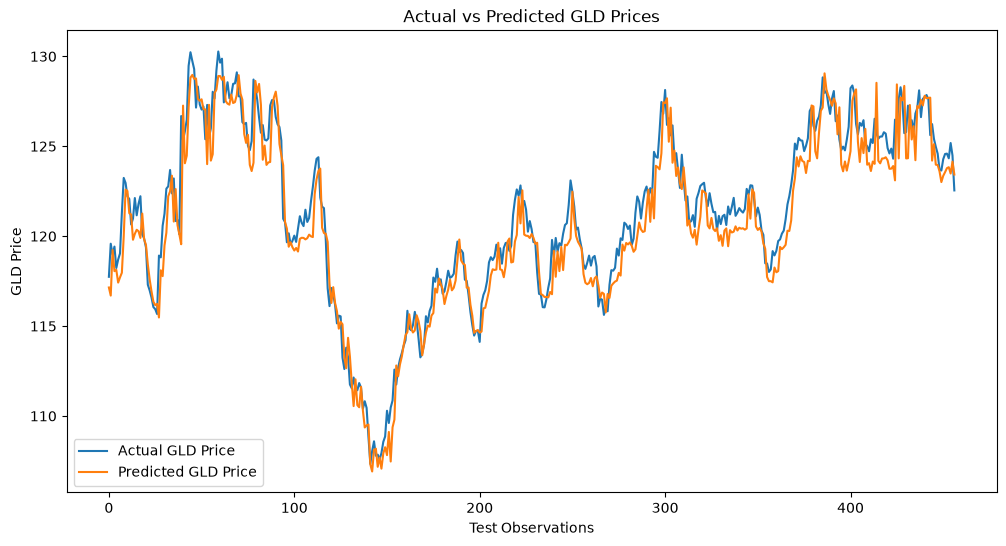

In [53]:
plt.figure(figsize=(12, 6))

plt.plot(
    y_test_features.values,
    label='Actual GLD Price'
)

plt.plot(
    rf_feature_predictions,
    label='Predicted GLD Price'
)

plt.title('Actual vs Predicted GLD Prices')
plt.xlabel('Test Observations')
plt.ylabel('GLD Price')
plt.legend()
plt.show()

In [54]:
import joblib

# Save the trained model
joblib.dump(rf_feature_model, 'gold_price_model.pkl')

print("Model saved successfully!")

Model saved successfully!
